In [9]:
from pathlib import Path
import pandas as pd

orders_file = next(Path("/content").rglob("orders*.csv"), None)
deliveries_file = next(Path("/content").rglob("deliveries*.csv"), None)

print("Orders file:", orders_file)
print("Deliveries file:", deliveries_file)

orders = pd.read_csv(orders_file)
deliveries = pd.read_csv(deliveries_file)

print("Orders shape:", orders.shape)
print("Deliveries shape:", deliveries.shape)

display(orders.head())
display(deliveries.head())

Orders file: /content/orders.csv
Deliveries file: /content/deliveries.csv
Orders shape: (400, 9)
Deliveries shape: (400, 6)


,id,address_id,created_at,delivery_fee,restaurant_id,status,tax_amount,total_amount,user_id
0,1,65,2025-06-25 20:24:04,2.99,40,delivered,0.97,16.08,6
1,2,53,2024-02-12 13:47:19,0.00,35,delivered,3.20,43.14,10
2,3,35,2025-11-12 20:33:19,1.99,23,delivered,6.39,88.30,21
3,4,43,2025-09-08 18:37:26,2.99,33,delivered,2.90,42.15,27
4,5,63,2024-11-13 11:20:14,1.99,41,delivered,2.06,29.85,13


,id,courier_id,delivered_at,order_id,picked_up_at,status
0,1,8,2025-07-15 19:28:17,122,2025-07-15 19:13:20,delivered
1,2,6,2025-10-18 09:05:26,291,2025-10-18 08:52:57,delivered
2,3,9,2025-03-08 20:11:02,109,2025-03-08 19:50:43,delivered
3,4,2,2025-11-05 18:04:25,349,2025-11-05 17:27:39,delivered
4,5,3,2025-07-16 20:50:08,252,2025-07-16 20:32:57,delivered


In [10]:
orders["created_at"] = pd.to_datetime(orders["created_at"])
deliveries["delivered_at"] = pd.to_datetime(deliveries["delivered_at"])

joined = orders.merge(
    deliveries, left_on="id", right_on="order_id",
    suffixes=("_order", "_delivery")
)

joined["duration_min"] = (
    joined["delivered_at"] - joined["created_at"]
).dt.total_seconds() / 60

checks = pd.DataFrame({
    "Check": [
        "Order rows", "Delivery rows",
        "Duplicate order IDs", "Duplicate delivery IDs",
        "Missing order values", "Missing delivery values",
        "Completed 2025 orders", "Negative durations"
    ],
    "Result": [
        len(orders), len(deliveries),
        orders["id"].duplicated().sum(),
        deliveries["id"].duplicated().sum(),
        orders.isna().sum().sum(),
        deliveries.isna().sum().sum(),
        ((joined["created_at"].dt.year == 2025) &
         (joined["status_order"] == "delivered") &
         (joined["status_delivery"] == "delivered")).sum(),
        (joined["duration_min"] < 0).sum()
    ]
})

display(checks)

,Check,Result
0,Order rows,400
1,Delivery rows,400
2,Duplicate order IDs,0
3,Duplicate delivery IDs,0
4,Missing order values,0
5,Missing delivery values,0
6,Completed 2025 orders,251
7,Negative durations,0


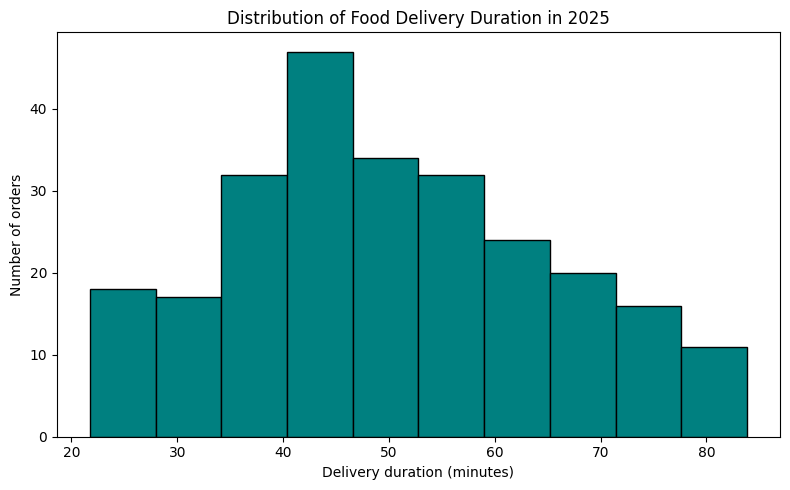

In [11]:
import matplotlib.pyplot as plt

data_2025 = joined[
    (joined["created_at"].dt.year == 2025) &
    (joined["status_order"] == "delivered") &
    (joined["status_delivery"] == "delivered")
].copy()

plt.figure(figsize=(8, 5))
plt.hist(data_2025["duration_min"], bins=10, color="teal", edgecolor="black")
plt.title("Distribution of Food Delivery Duration in 2025")
plt.xlabel("Delivery duration (minutes)")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

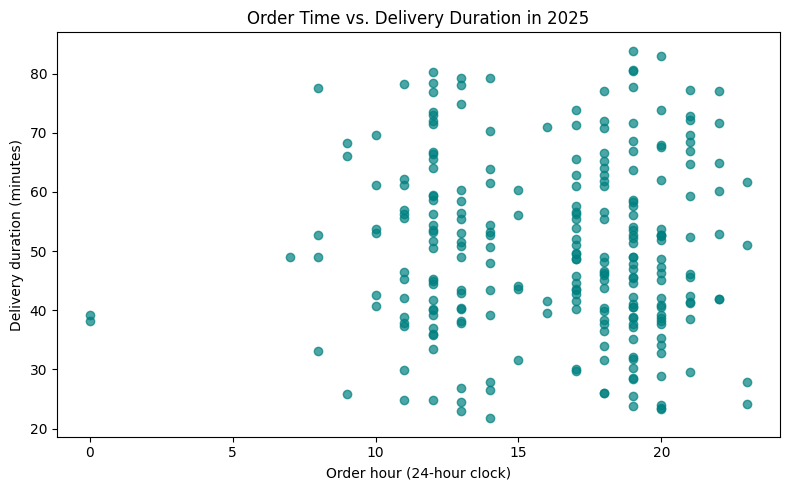

In [12]:
data_2025["order_hour"] = data_2025["created_at"].dt.hour

plt.figure(figsize=(8, 5))
plt.scatter(
    data_2025["order_hour"],
    data_2025["duration_min"],
    color="teal",
    alpha=0.7
)
plt.title("Order Time vs. Delivery Duration in 2025")
plt.xlabel("Order hour (24-hour clock)")
plt.ylabel("Delivery duration (minutes)")
plt.tight_layout()
plt.show()

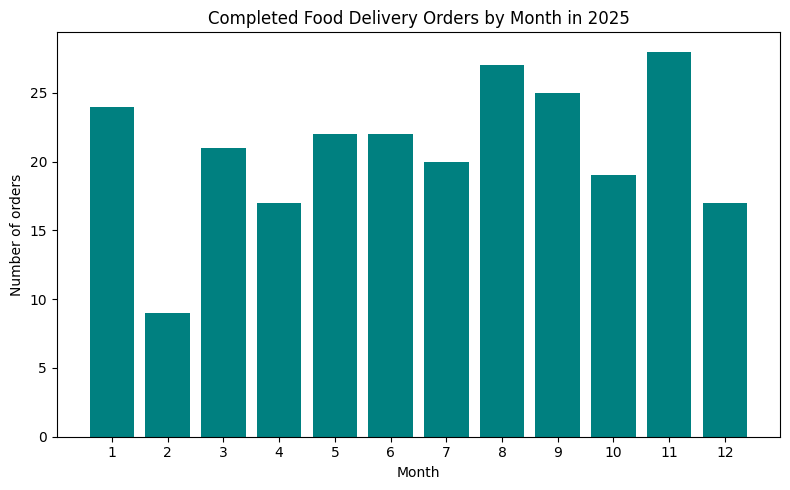

In [13]:
monthly_orders = (
    data_2025["created_at"]
    .dt.month
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 5))
plt.bar(monthly_orders.index, monthly_orders.values, color="teal")
plt.title("Completed Food Delivery Orders by Month in 2025")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

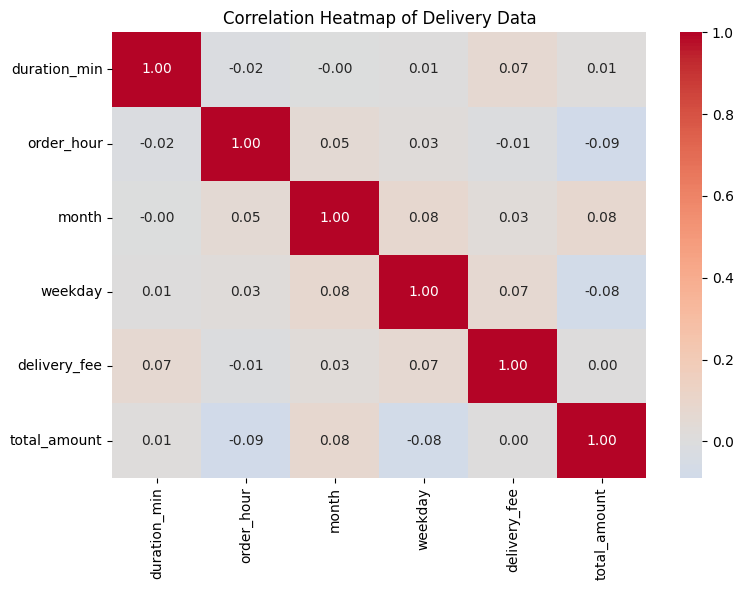

In [14]:
import seaborn as sns

corr_data = data_2025.copy()
corr_data["order_hour"] = corr_data["created_at"].dt.hour
corr_data["month"] = corr_data["created_at"].dt.month
corr_data["weekday"] = corr_data["created_at"].dt.dayofweek

columns = [
    "duration_min", "order_hour", "month",
    "weekday", "delivery_fee", "total_amount"
]

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_data[columns].corr(),
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)
plt.title("Correlation Heatmap of Delivery Data")
plt.tight_layout()
plt.show()

In [15]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model_data = data_2025.copy()
model_data["order_hour"] = model_data["created_at"].dt.hour
model_data["month"] = model_data["created_at"].dt.month
model_data["weekday"] = model_data["created_at"].dt.dayofweek

features = ["order_hour", "month", "weekday", "delivery_fee", "total_amount"]
train = model_data["month"] <= 8
test = model_data["month"] >= 9

X_train = model_data.loc[train, features]
X_test = model_data.loc[test, features]
y_train = model_data.loc[train, "duration_min"]
y_test = model_data.loc[test, "duration_min"]

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

baseline = np.full(len(y_test), y_train.mean())

results = pd.DataFrame({
    "Model": ["Mean baseline", "Linear regression"],
    "MAE (minutes)": [
        mean_absolute_error(y_test, baseline),
        mean_absolute_error(y_test, predictions)
    ],
    "RMSE (minutes)": [
        mean_squared_error(y_test, baseline) ** 0.5,
        mean_squared_error(y_test, predictions) ** 0.5
    ]
})

display(results)
print("Linear regression R²:", round(r2_score(y_test, predictions), 3))

,Model,MAE (minutes),RMSE (minutes)
0,Mean baseline,13.066496,15.708926
1,Linear regression,13.966489,16.738745


Linear regression R²: -0.135


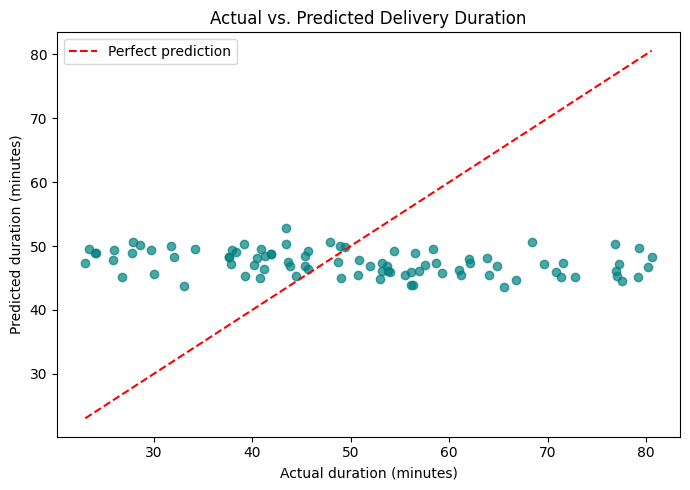

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions, color="teal", alpha=0.7)

low = min(y_test.min(), predictions.min())
high = max(y_test.max(), predictions.max())
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.title("Actual vs. Predicted Delivery Duration")
plt.xlabel("Actual duration (minutes)")
plt.ylabel("Predicted duration (minutes)")
plt.legend()
plt.tight_layout()
plt.show()